#  1. Data Loading, Merging & Deep Exploration

In [39]:
# Import Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime

import warnings
warnings.filterwarnings('ignore')

# Display Settings
pd.set_option('display.max_columns', None)

plt.style.use('seaborn-v0_8')

In [40]:
# Load Datasets
df= pd.read_csv('train.csv')

In [41]:
#Dataset Shape
print("Rows :", df.shape[0])
print("Columns :", df.shape[1])

Rows : 9800
Columns : 18


In [42]:
df.head(10)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680
5,6,CA-2015-115812,09/06/2015,14/06/2015,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032.0,West,FUR-FU-10001487,Furniture,Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.8600
6,7,CA-2015-115812,09/06/2015,14/06/2015,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032.0,West,OFF-AR-10002833,Office Supplies,Art,Newell 322,7.2800
7,8,CA-2015-115812,09/06/2015,14/06/2015,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032.0,West,TEC-PH-10002275,Technology,Phones,Mitel 5320 IP Phone VoIP phone,907.1520
8,9,CA-2015-115812,09/06/2015,14/06/2015,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032.0,West,OFF-BI-10003910,Office Supplies,Binders,DXL Angle-View Binders with Locking Rings by S...,18.5040
9,10,CA-2015-115812,09/06/2015,14/06/2015,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032.0,West,OFF-AP-10002892,Office Supplies,Appliances,Belkin F5C206VTEL 6 Outlet Surge,114.9000


In [43]:
# Information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   object 
 2   Order Date     9800 non-null   object 
 3   Ship Date      9800 non-null   object 
 4   Ship Mode      9800 non-null   object 
 5   Customer ID    9800 non-null   object 
 6   Customer Name  9800 non-null   object 
 7   Segment        9800 non-null   object 
 8   Country        9800 non-null   object 
 9   City           9800 non-null   object 
 10  State          9800 non-null   object 
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   object 
 13  Product ID     9800 non-null   object 
 14  Category       9800 non-null   object 
 15  Sub-Category   9800 non-null   object 
 16  Product Name   9800 non-null   object 
 17  Sales          9800 non-null   float64
dtypes: float

In [44]:
# Missing Values
df.isnull().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
dtype: int64

In [45]:
# Remove missing Values
df.drop('Postal Code', axis=1, inplace=True)

- The dataset contained 11 missing values only in the Postal Code column. Since Postal Code is an identifier and does not contribute to sales forecasting or demand analysis, the column was removed from the dataset. No other missing values or data quality issues were found.

In [46]:
# Duplicate Rows
df.duplicated().sum()

np.int64(0)

### Observation

- The dataset contains 9800 rows and 18 columns.
- No major missing values were observed.
- Duplicate rows: 0 .
- Order Date and Ship Date need to be converted into datetime format.

In [47]:
# Date Conversion
df['Order Date'] = pd.to_datetime(df['Order Date'], dayfirst=True)

df['Ship Date'] = pd.to_datetime(df['Ship Date'], dayfirst=True)

In [48]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9800 non-null   int64         
 1   Order ID       9800 non-null   object        
 2   Order Date     9800 non-null   datetime64[ns]
 3   Ship Date      9800 non-null   datetime64[ns]
 4   Ship Mode      9800 non-null   object        
 5   Customer ID    9800 non-null   object        
 6   Customer Name  9800 non-null   object        
 7   Segment        9800 non-null   object        
 8   Country        9800 non-null   object        
 9   City           9800 non-null   object        
 10  State          9800 non-null   object        
 11  Region         9800 non-null   object        
 12  Product ID     9800 non-null   object        
 13  Category       9800 non-null   object        
 14  Sub-Category   9800 non-null   object        
 15  Product Name   9800 n

In [49]:
# Extract time features : Year, Month, Week Number, Day of Week, Quarter, Season

# Year
df['Year'] = df['Order Date'].dt.year

# Month
df['Month'] = df['Order Date'].dt.month
df['Month Name'] = df['Order Date'].dt.month_name()

# Weel Number
df['Week'] = df['Order Date'].dt.isocalendar().week

# Day of Week
df['Day of Week'] = df['Order Date'].dt.day_name()

# Quarter
df['Quarter'] = df['Order Date'].dt.quarter

# Season
def season(month):

    if month in [12,1,2]:
        return "Winter"

    elif month in [3,4,5]:
        return "Summer"

    elif month in [6,7,8]:
        return "Monsoon"

    else:
        return "Autumn"

df['Season'] = df['Month'].apply(season)

In [50]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Region,Product ID,Category,Sub-Category,Product Name,Sales,Year,Month,Month Name,Week,Day of Week,Quarter,Season
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2017,11,November,45,Wednesday,4,Autumn
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,2017,11,November,45,Wednesday,4,Autumn
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2017,6,June,24,Monday,2,Monsoon
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,2016,10,October,41,Tuesday,4,Autumn
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2016,10,October,41,Tuesday,4,Autumn


In [51]:
# Aggregate daily sales into weekly and monthly totals(We will need both granularities for different models)

# Daily Sales
daily_sales = df.groupby('Order Date')['Sales'].sum().reset_index()

daily_sales.head()

,Order Date,Sales
0,2015-01-03,16.448
1,2015-01-04,288.060
2,2015-01-05,19.536
3,2015-01-06,4407.100
4,2015-01-07,87.158


In [52]:
# Weekly Sales
weekly_sales = (
    df.groupby(
        pd.Grouper(
            key='Order Date',
            freq='W'
        )
    )['Sales']
    .sum()
    .reset_index()
)

weekly_sales.head()

,Order Date,Sales
0,2015-01-04,304.508
1,2015-01-11,4619.108
2,2015-01-18,4130.533
3,2015-01-25,3092.544
4,2015-02-01,2527.914


In [53]:
# Monthly Sales
monthly_sales = (
    df.groupby(
        pd.Grouper(
            key='Order Date',
            freq='M'
        )
    )['Sales']
    .sum()
    .reset_index()
)

monthly_sales.head()

,Order Date,Sales
0,2015-01-31,14205.707
1,2015-02-28,4519.892
2,2015-03-31,55205.797
3,2015-04-30,27906.855
4,2015-05-31,23644.303


- Q) Which product category generates the highest total revenue?

In [54]:
category_sales = (
    df.groupby('Category')['Sales']
    .sum()
    .sort_values(ascending=False)
)

category_sales

Category
Technology         827455.8730
Furniture          728658.5757
Office Supplies    705422.3340
Name: Sales, dtype: float64

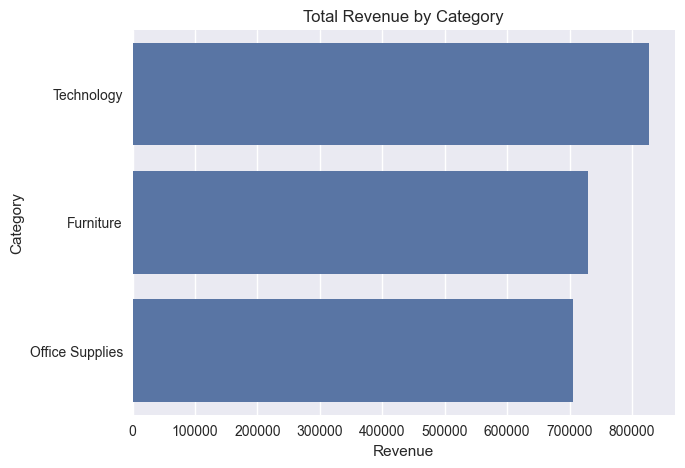

In [55]:
# Bar Plot
plt.figure(figsize=(7,5))

sns.barplot(
    x=category_sales.values,
    y=category_sales.index
)

plt.title("Total Revenue by Category")

plt.xlabel("Revenue")

plt.ylabel("Category")

plt.show()

- Technology generated the highest total revenue ($827,455.87), contributing more sales than both Furniture ($728,658.58) and Office Supplies ($705,422.33). This suggests that technology products are the primary revenue drivers for the business and should be prioritized for inventory planning, promotions, and demand forecasting.

- Q) Which region has the most consistent sales growth over 4 years?

In [56]:
# Yearly Sales by Region
region_yearly_sales = (
    df.groupby(['Year', 'Region'])['Sales']
      .sum()
      .reset_index()
)

region_yearly_sales

,Year,Region,Sales
0,2015,Central,102920.5206
1,2015,East,127652.8190
2,2015,South,103374.9055
3,2015,West,145907.9630
4,2016,Central,102425.1724
5,2016,East,153225.1830
6,2016,South,70076.0825
7,2016,West,133709.5675
8,2017,Central,145673.8800
9,2017,East,178511.5380


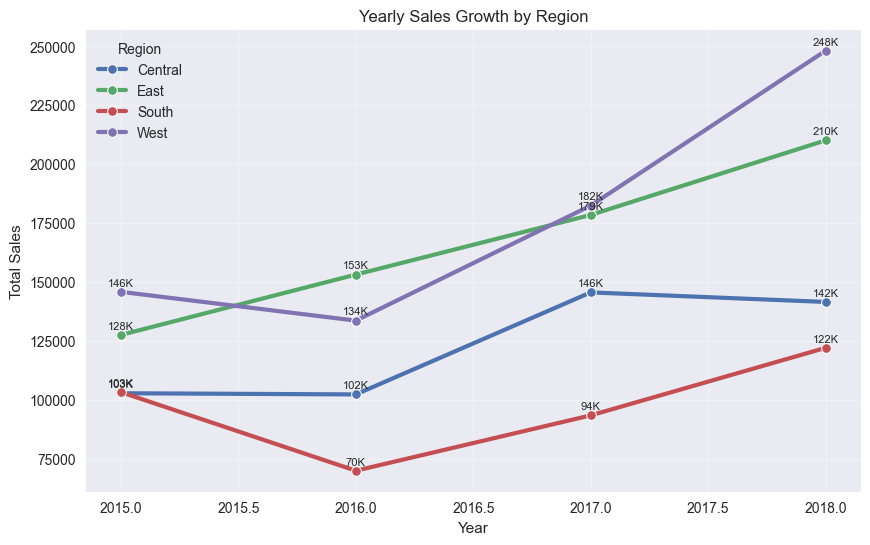

In [57]:
# Line Plot 
plt.figure(figsize=(10,6))

sns.lineplot(
    data=region_yearly_sales,
    x='Year',
    y='Sales',
    hue='Region',
    marker='o',
    linewidth=3
)

for line in plt.gca().lines:
    for x, y in zip(line.get_xdata(), line.get_ydata()):
        plt.text(
            x,
            y + 2500,
            f'{y/1000:.0f}K',
            fontsize=8,
            ha='center'
        )

plt.title('Yearly Sales Growth by Region')
plt.xlabel('Year')
plt.ylabel('Total Sales')
plt.grid(alpha=0.3)
plt.legend(title='Region')

plt.show()

- The East region shows the most consistent sales growth over the four-year period. Sales increased steadily every year, rising from approximately 127K in 2015 to 210K in 2018, without any major decline. In comparison, the West region achieved the highest overall sales by 2018 but experienced a decline from 2015 to 2016 before growing rapidly afterward. The Central and South regions also showed fluctuations during the four years. Therefore, the East region demonstrates the most stable and consistent sales growth, making it the strongest region in terms of long-term performance.

- The steady growth in the East region indicates stable customer demand and effective sales performance. The company should continue investing in this region through inventory expansion, targeted marketing campaigns, and customer retention initiatives. Although the West region generates the highest sales in the later years, its larger fluctuations suggest that demand forecasting and inventory planning should be monitored more closely to maintain sustainable growth.

- Q) What is the average time between Order Date and Ship Date — and does it vary by region?


In [58]:
# Average Shipping time
df['Shipping Days'] = (
    df['Ship Date']-
    df['Order Date']
).dt.days

avg_time = df['Shipping Days'].mean()
print("Average time(Days) between Order Date and Ship Date : ", avg_time)

Average time(Days) between Order Date and Ship Date :  3.9611224489795918


In [59]:
# Region-wise
shipping = (
    df.groupby('Region')['Shipping Days']
    .mean()
    .sort_values()
)

shipping

Region
East       3.910233
West       3.930255
South      3.961202
Central    4.065876
Name: Shipping Days, dtype: float64

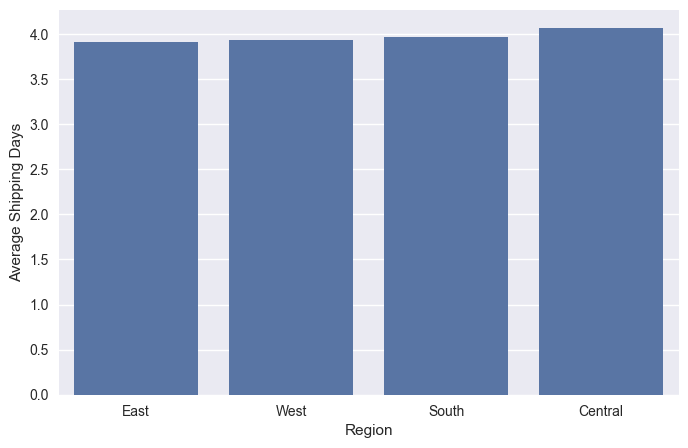

In [60]:
# Bar plot
plt.figure(figsize=(8,5))

sns.barplot(
    x=shipping.index,
    y=shipping.values
)

plt.ylabel("Average Shipping Days")

plt.show()

- The average shipping time is approximately 4 days across all regions, indicating a fairly consistent logistics process. The East region has the fastest average delivery (3.91 days), while the Central region takes slightly longer (4.07 days). Since the difference is only around 0.15 days, shipping performance appears to be consistent across regions.
- Since shipping times are nearly identical across regions, logistics is unlikely to be a major factor affecting sales differences. The company should instead focus on improving demand forecasting, inventory planning, and regional sales strategies.

- Q) Are there months that consistently spike(seasonality)?

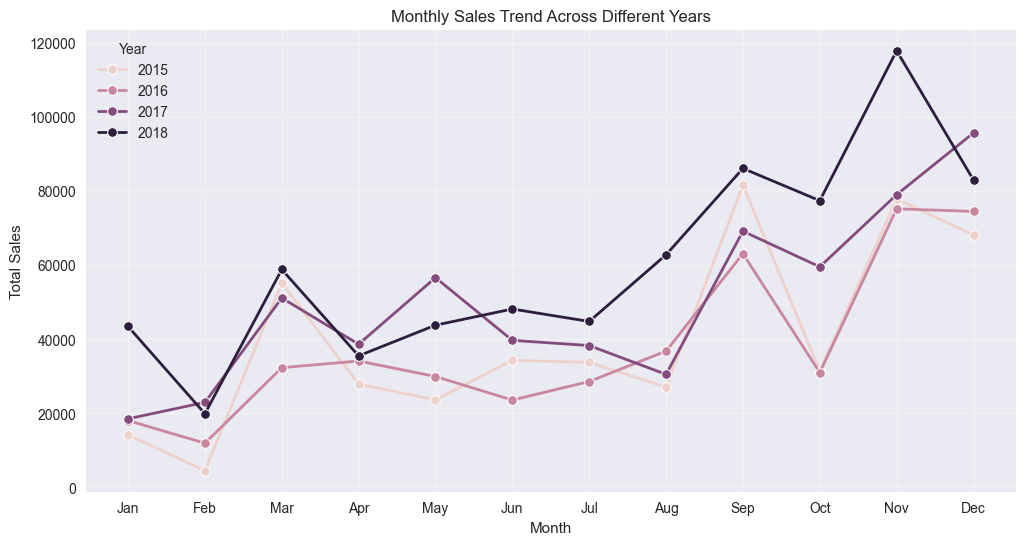

In [61]:
# Monthly sales for each year
monthly_sales = (
    df.groupby(['Year', 'Month'])['Sales']
      .sum()
      .reset_index()
)

# Month names for better labels
month_names = {
    1:'Jan', 2:'Feb', 3:'Mar', 4:'Apr',
    5:'May', 6:'Jun', 7:'Jul', 8:'Aug',
    9:'Sep', 10:'Oct', 11:'Nov', 12:'Dec'
}

monthly_sales['Month Name'] = monthly_sales['Month'].map(month_names)

# Correct month order
month_order = ['Jan','Feb','Mar','Apr','May','Jun',
               'Jul','Aug','Sep','Oct','Nov','Dec']

plt.figure(figsize=(12,6))

sns.lineplot(
    data=monthly_sales,
    x='Month Name',
    y='Sales',
    hue='Year',
    marker='o',
    linewidth=2
)

plt.xticks(range(12), month_order)
plt.title('Monthly Sales Trend Across Different Years')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.grid(alpha=0.3)

plt.show()

- Yes. The monthly sales trend shows a clear seasonal pattern across all four years. Sales generally begin to increase from August and remain high through September, November, and December. Among all months, November consistently records the highest sales, making it the strongest sales month across the dataset. In contrast, January and February show the lowest sales in most years. This pattern suggests that customer demand increases significantly during the final quarter of the year, likely due to festive shopping, holiday promotions, and year-end purchasing behavior.

- Since demand consistently rises during September–December, the company should increase inventory levels, warehouse capacity, and staffing before this period. Marketing campaigns, promotional offers, and product launches should also be planned during these months to maximize revenue. The lower-demand months, particularly January and February, can be used for inventory clearance, maintenance, and operational planning.

# 2. Time Series Analysis & Decomposition


In [62]:
monthly_ts = (
    df.groupby(pd.Grouper(key='Order Date', freq='M'))['Sales']
    .sum()
)
monthly_ts.head()

Order Date
2015-01-31    14205.707
2015-02-28     4519.892
2015-03-31    55205.797
2015-04-30    27906.855
2015-05-31    23644.303
Freq: ME, Name: Sales, dtype: float64

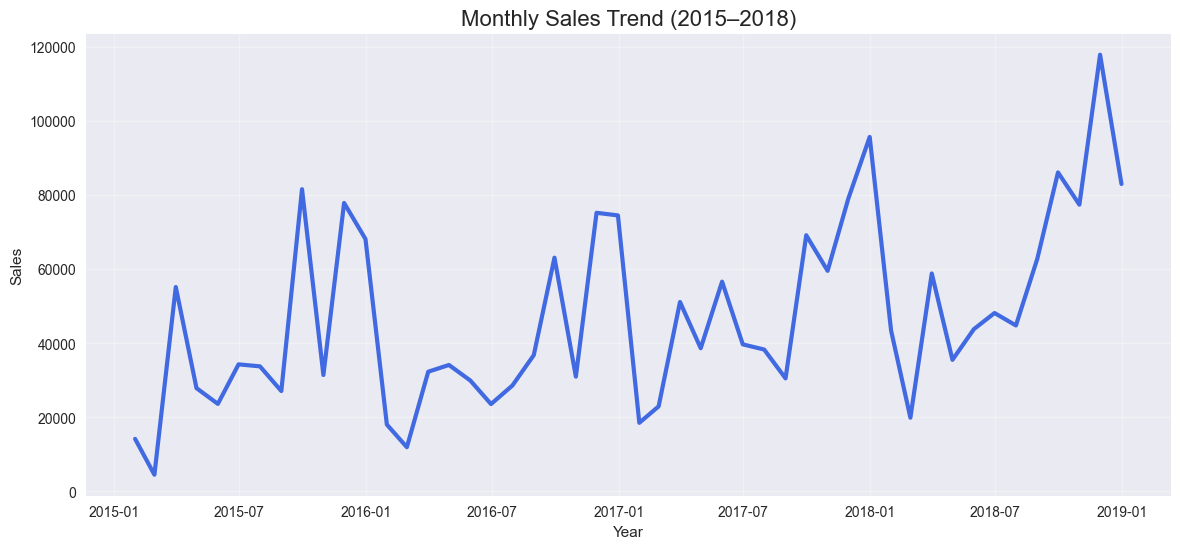

In [63]:
# Plot Monthly Sales Trend
plt.figure(figsize=(14,6))

plt.plot(
    monthly_ts,
    linewidth=3,
    color='royalblue'
)

plt.title("Monthly Sales Trend (2015–2018)", fontsize=16)

plt.xlabel("Year")

plt.ylabel("Sales")

plt.grid(alpha=0.3)

plt.show()


- The increasing sales trend indicates that the business is expanding over time. However, the recurring peaks near the end of each year suggest that demand is seasonal. Inventory planning, staffing, and promotional campaigns should therefore be aligned with these high-demand periods to maximize revenue and avoid stock shortages.

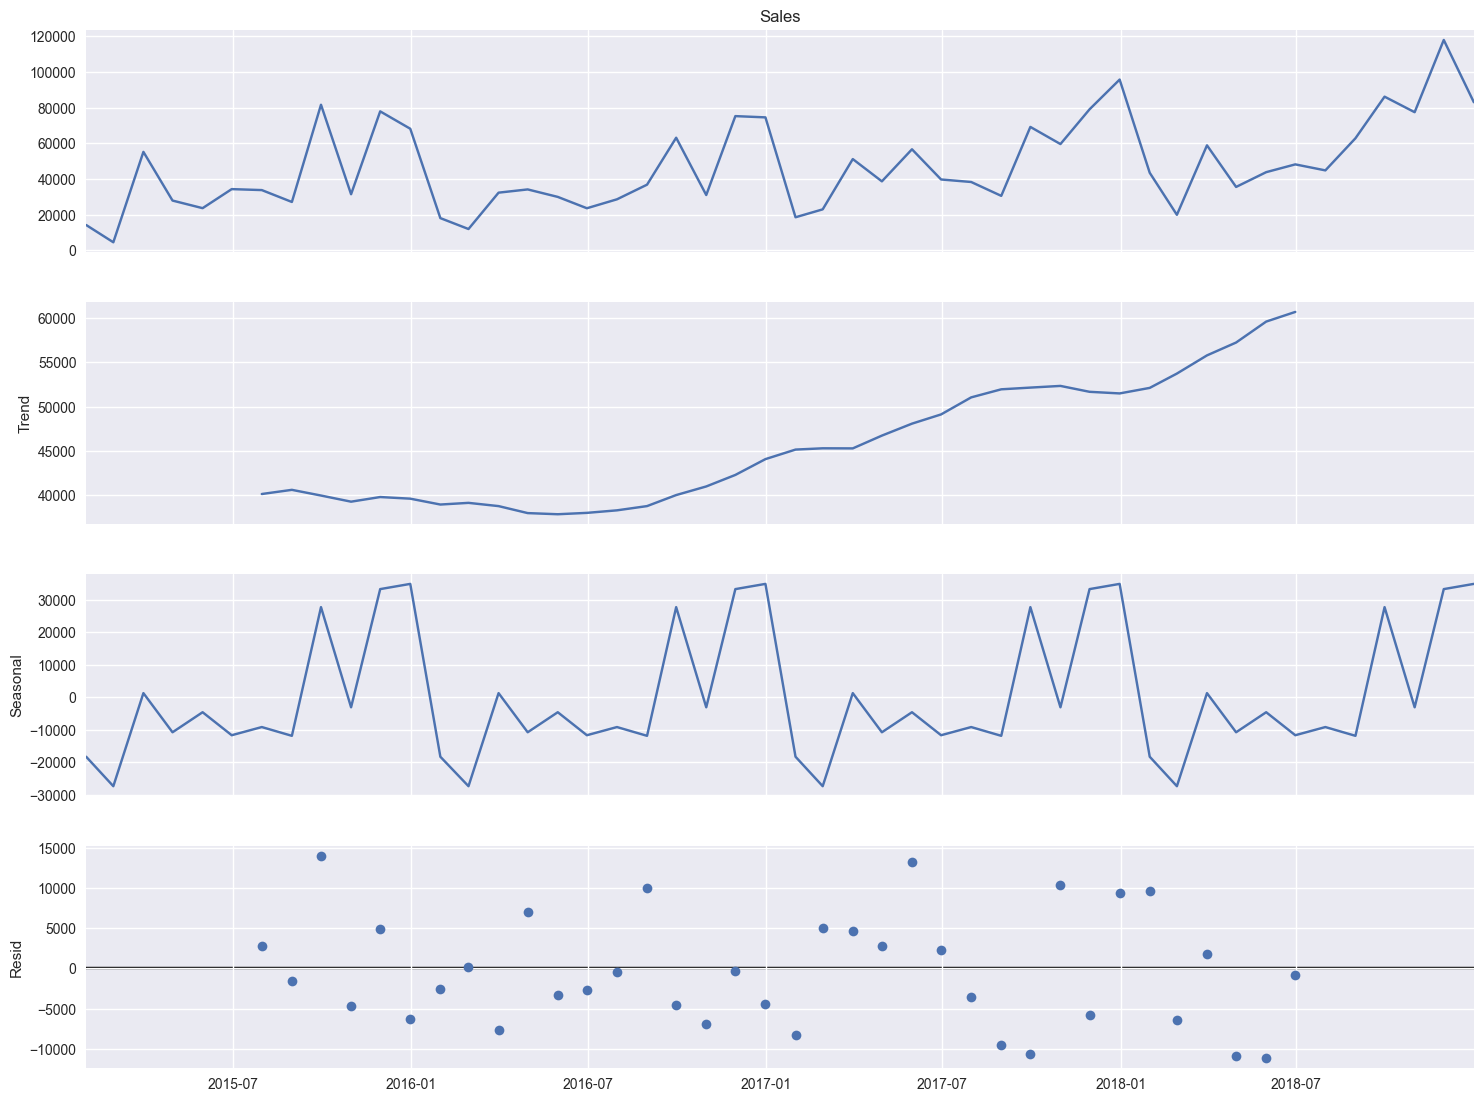

In [64]:
# Time Series Decomposition
from statsmodels.tsa.seasonal import seasonal_decompose

decompose = seasonal_decompose(
    monthly_ts,
    model = 'additive',
    period=12
)

fig = decompose.plot()
fig.set_size_inches(16,12)
plt.show()

what does the trend tell you? Is seasonality strong or weak? What months show the highest residual noise?
 1. The trend component shows a steady increase in sales from 2015 to 2018, indicating continuous business growth over time.

2. Yes seasonality is strong, the seasonal component exhibits a clear repeating yearly pattern, confirming that sales are influenced by seasonal demand.

3. The residual component mostly fluctuates around zero, but a few months show unusually high positive or negative residuals, suggesting unexpected sales events or external factors.

4. Since both trend and seasonality are clearly visible, forecasting models that incorporate seasonal behavior, such as SARIMA and Prophet, are appropriate for predicting future sales.

In [65]:
# ADF Test
from statsmodels.tsa.stattools import adfuller

result = adfuller(monthly_ts)

print("ADF Statistic :", result[0])
print("p-value :", result[1])

print("\nCritical Values:")
for key, value in result[4].items():
    print(f"{key}: {value:.4f}")

ADF Statistic : -4.416136761430769
p-value : 0.00027791039276670623

Critical Values:
1%: -3.5778
5%: -2.9253
10%: -2.6008


What does Stationarity mean? 

- A stationary time series is one whose statistical properties, such as the average value and variation, remain relatively stable over time. Forecasting models like ARIMA and SARIMA work best when the data is stationary because the underlying patterns remain consistent, making future predictions more reliable.

Interpretation of the ADF Test 

- The Augmented Dickey-Fuller (ADF) test was used to check whether the monthly sales data was stationary. The test produced an ADF statistic of -4.416 and a p-value of 0.000278. Since the p-value is less than 0.05, the null hypothesis of non-stationarity is rejected. This indicates that the original monthly sales series is already stationary, making it suitable for time series forecasting.

### Here series is stationary that's why we don't need to apply differencing

# 3. Sales Forecasting using 3 Different Models


In [66]:
# Train-Test Split

# Last 3 months will be used for testing
train = monthly_ts[:-3]
test = monthly_ts[-3:]

print("Training Months :", len(train))
print("Testing Months :", len(test))

Training Months : 45
Testing Months : 3


### Model 1 — SARIMA (Statistical Model)

In [67]:
# Build SARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

sarima = SARIMAX(
    train,
    order = (1,1,1),
    seasonal_order= (1,1,1,12)
)

sarima_fit = sarima.fit()
print(sarima_fit.summary())


                                     SARIMAX Results                                      
Dep. Variable:                              Sales   No. Observations:                   45
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -347.979
Date:                            Sun, 12 Jul 2026   AIC                            705.958
Time:                                    19:36:46   BIC                            713.287
Sample:                                01-31-2015   HQIC                           708.387
                                     - 09-30-2018                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5680      0.242      2.347      0.019       0.094       1.042
ma.L1         -0.8985      0.177   

### why we chose them

Chosen Model: SARIMA(1,1,1)(1,1,1,12)

The parameters were selected based on the characteristics of the monthly sales data and the results of the time series analysis.

- p = 1: Uses the previous month's sales to capture short-term dependencies.
- d = 1: Applies first-order differencing to reduce long-term trends and stabilize the series.
- q = 1: Uses the previous forecast error to improve current predictions.
- P = 1: Captures seasonal dependence from the previous yearly cycle.
- D = 1: Removes yearly seasonal trends through seasonal differencing.
- Q = 1: Accounts for seasonal forecast errors.
- m = 12: Since the data is monthly, a seasonal period of 12 represents one complete year.

These values were chosen as a strong baseline because the decomposition analysis showed both an upward trend and clear yearly seasonality.

In [68]:
# Forecast
sarima_forecast = sarima_fit.get_forecast(steps=3)
sarima_pred = sarima_forecast.predicted_mean
confidence = sarima_forecast.conf_int(alpha=0.05)

confidence

,lower Sales,upper Sales
2018-10-31,39684.152691,92671.052206
2018-11-30,60156.119147,123942.380202
2018-12-31,65602.109264,134328.228163


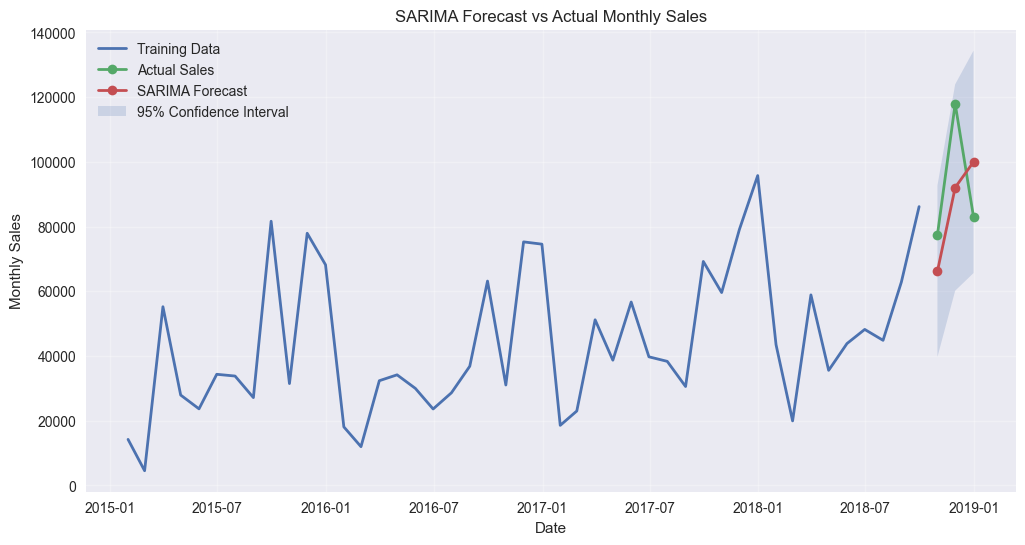

In [69]:
plt.figure(figsize=(12,6))

plt.plot(train.index, train, label='Training Data', linewidth=2)

plt.plot(test.index, test, label='Actual Sales',
         marker='o', linewidth=2)

plt.plot(test.index, sarima_pred,
         label='SARIMA Forecast',
         marker='o',
         linewidth=2)

plt.fill_between(
    confidence.index,
    confidence.iloc[:,0],
    confidence.iloc[:,1],
    alpha=0.2,
    label='95% Confidence Interval'
)

plt.title('SARIMA Forecast vs Actual Monthly Sales')
plt.xlabel('Date')
plt.ylabel('Monthly Sales')
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [70]:
# Evaluation
from sklearn.metrics import mean_absolute_error

from sklearn.metrics import root_mean_squared_error

from sklearn.metrics import mean_absolute_percentage_error

import numpy as np

In [71]:
sarima_mae = mean_absolute_error(
    test,
    sarima_pred
)

sarima_rmse = root_mean_squared_error(
        test,
        sarima_pred
    )


sarima_mape = mean_absolute_percentage_error(
    test,
    sarima_pred
)

print("Mean Absolute Error : ", sarima_mae)
print("Root Mean Squared Error : ", sarima_rmse)
print("Mean Absolute Percentage Error : ", sarima_mape)

Mean Absolute Error :  18031.40466334434
Root Mean Squared Error :  19009.182061964573
Mean Absolute Percentage Error :  0.18966498056182965


- The SARIMA model successfully captured the overall trend and yearly seasonality present in the monthly sales data. The predicted values followed the actual sales pattern reasonably well, and all forecasts remained within the 95% confidence interval. The model achieved a Mean Absolute Error (MAE) of approximately 18,031, an RMSE of approximately 19,009, and a MAPE of 18.97%, indicating satisfactory short-term forecasting performance.

### Model 2 — Facebook Prophet (Industry-standard Forecasting Tool)

- Facebook Prophet is an additive time series forecasting model designed for business forecasting problems. It automatically captures long-term trends, yearly seasonality, weekly seasonality, holidays, and missing values with very little parameter tuning. Prophet is widely used because it performs well on real-world business data and is easy to interpret.

In [72]:
# Prepare train data for Prophet
prophet_train = train.reset_index()

prophet_train.columns = ['ds', 'y']

prophet_train.head()

,ds,y
0,2015-01-31,14205.707
1,2015-02-28,4519.892
2,2015-03-31,55205.797
3,2015-04-30,27906.855
4,2015-05-31,23644.303


In [75]:
%pip install prophet

  Using cached prophet-1.3.0-py3-none-win_amd64.whl.metadata (3.6 kB)
  Using cached cmdstanpy-1.3.0-py3-none-any.whl.metadata (4.2 kB)
  Using cached holidays-0.100-py3-none-any.whl.metadata (53 kB)
  Using cached importlib_resources-7.1.0-py3-none-any.whl.metadata (4.0 kB)
  Using cached stanio-0.5.1-py3-none-any.whl.metadata (1.6 kB)
Using cached prophet-1.3.0-py3-none-win_amd64.whl (12.1 MB)
Using cached holidays-0.100-py3-none-any.whl (1.5 MB)
Using cached cmdstanpy-1.3.0-py3-none-any.whl (99 kB)
Using cached stanio-0.5.1-py3-none-any.whl (8.1 kB)
Using cached importlib_resources-7.1.0-py3-none-any.whl (37 kB)

   -------- ------------------------------- 1/5 [importlib_resources]
   ---------------- ----------------------- 2/5 [holidays]
   ---------------- ----------------------- 2/5 [holidays]
   ---------------- ----------------------- 2/5 [holidays]
   ---------------- ----------------------- 2/5 [holidays]
   ---------------- ----------------------- 2/5 [holidays]
   --------

In [76]:
# Train the Prophet Model
from prophet import Prophet

model =  Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False
)

model.fit(prophet_train)

model_weekly =  Prophet(
    yearly_seasonality=False,
    weekly_seasonality=True,
    daily_seasonality=False
)

model_weekly.fit(prophet_train)

19:42:18 - cmdstanpy - INFO - Chain [1] start processing
19:42:19 - cmdstanpy - INFO - Chain [1] done processing
19:42:19 - cmdstanpy - INFO - Chain [1] start processing
19:42:19 - cmdstanpy - INFO - Chain [1] done processing


- Prophet was configured with yearly seasonality enabled because the sales data is aggregated monthly and the decomposition analysis revealed a clear yearly seasonal pattern. Weekly and daily seasonality were disabled because monthly aggregated data does not contain sufficient information to learn weekly or daily patterns.

In [77]:
# Forcast Yearly

future = model.make_future_dataframe(
    periods=3,
    freq='M'
)

forecast = model.predict(future)

forecast.tail()

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,yearly,yearly_lower,yearly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
43,2018-08-31,54942.277806,39053.023516,55408.866150,54942.277806,54942.277806,-7670.719569,-7670.719569,-7670.719569,-7670.719569,-7670.719569,-7670.719569,0.0,0.0,0.0,47271.558236
44,2018-09-30,55441.608196,78237.437345,94118.529091,55441.608196,55441.608196,31172.345120,31172.345120,31172.345120,31172.345120,31172.345120,31172.345120,0.0,0.0,0.0,86613.953316
45,2018-10-31,55957.582932,43422.662614,59025.749975,55957.411230,55957.728147,-4638.639074,-4638.639074,-4638.639074,-4638.639074,-4638.639074,-4638.639074,0.0,0.0,0.0,51318.943858
46,2018-11-30,56456.913322,82363.592584,98888.848181,56456.398271,56457.377589,33868.741461,33868.741461,33868.741461,33868.741461,33868.741461,33868.741461,0.0,0.0,0.0,90325.654784
47,2018-12-31,56972.888059,82118.139058,98216.492093,56971.826647,56973.832028,33068.196420,33068.196420,33068.196420,33068.196420,33068.196420,33068.196420,0.0,0.0,0.0,90041.084479


In [78]:
# Forcast weekly
future_weekly = model_weekly.make_future_dataframe(
    periods=3,
    freq='M'
)

forecast_weekly = model_weekly.predict(future_weekly)


In [79]:
# 3-Months Forcast
forecast[['ds','yhat','yhat_lower','yhat_upper']].tail(3)

,ds,yhat,yhat_lower,yhat_upper
45,2018-10-31,51318.943858,43422.662614,59025.749975
46,2018-11-30,90325.654784,82363.592584,98888.848181
47,2018-12-31,90041.084479,82118.139058,98216.492093


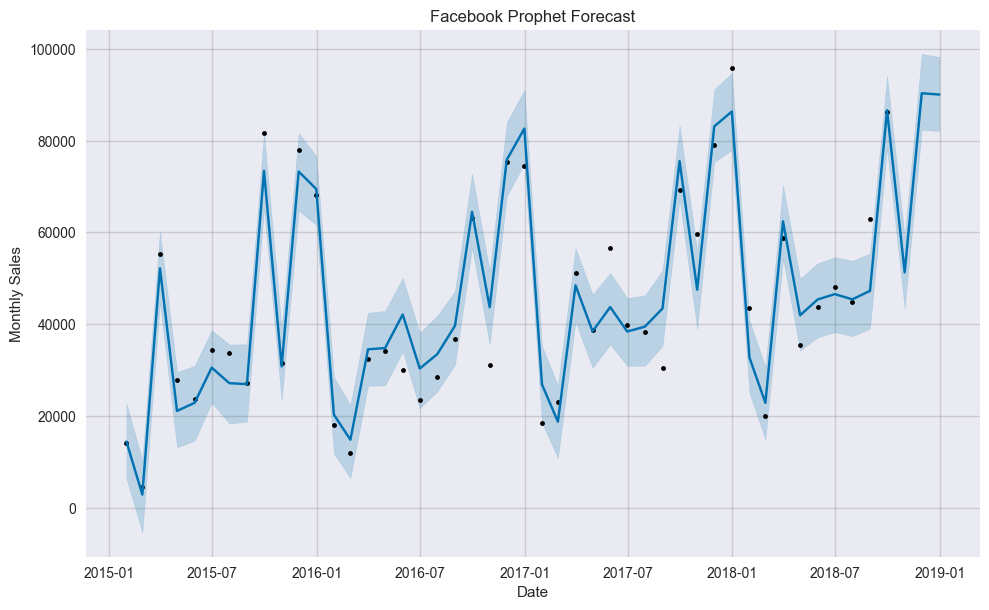

In [80]:
# Plot Forecast yearly
fig1 = model.plot(forecast)

plt.title("Facebook Prophet Forecast")

plt.xlabel("Date")

plt.ylabel("Monthly Sales")

plt.grid(alpha=0.3)

plt.show()

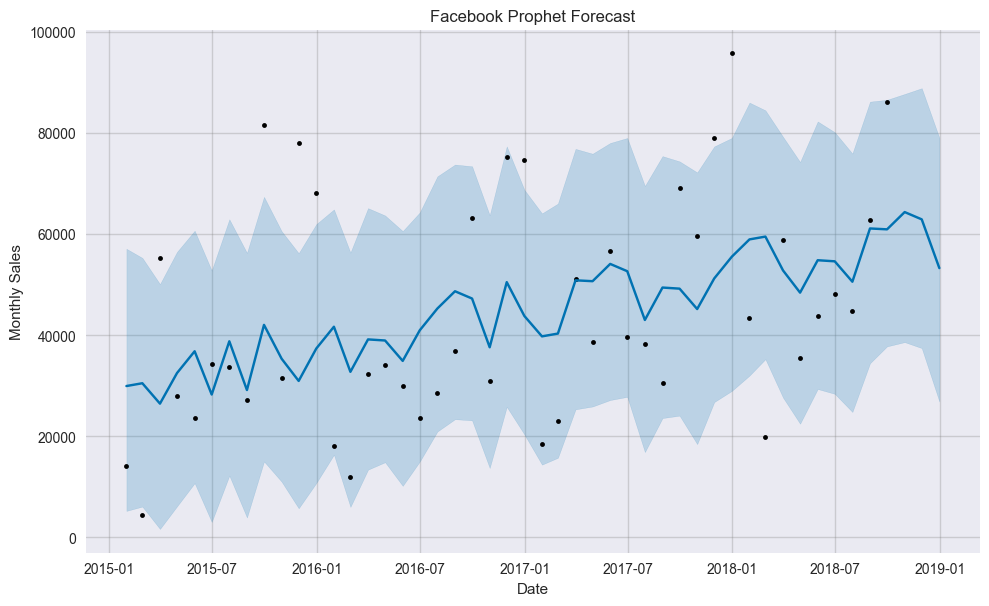

In [81]:
# Plot Forecast weekly
fig2 = model_weekly.plot(forecast_weekly)

plt.title("Facebook Prophet Forecast")

plt.xlabel("Date")

plt.ylabel("Monthly Sales")

plt.grid(alpha=0.3)

plt.show()

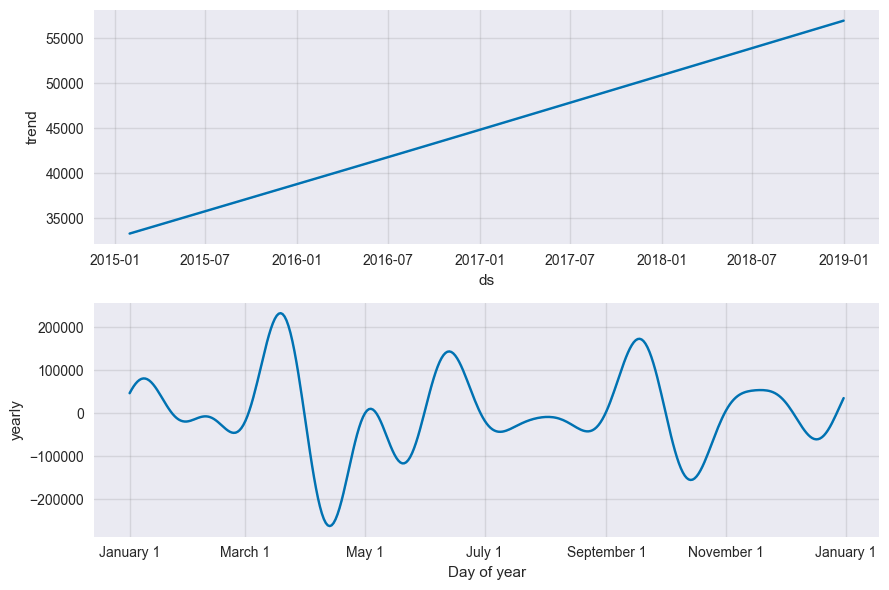

In [82]:
# Plot Trend & Seasonality
fig3 = model.plot_components(forecast)

plt.show()

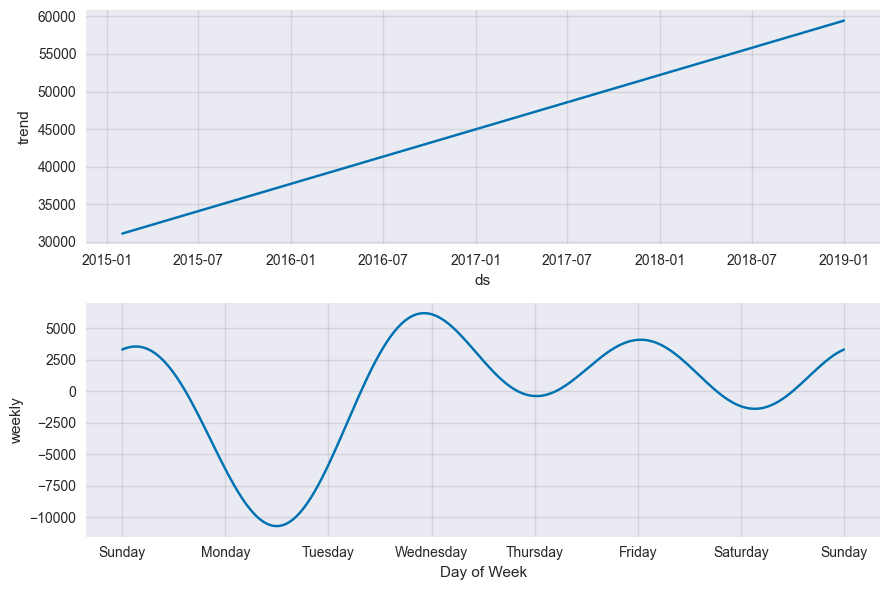

In [83]:
# Plot Trend & Seasonality for weekly
fig4 = model_weekly.plot_components(forecast_weekly)

plt.show()

In [84]:
# Evaluate Prophet

prophet_pred = forecast['yhat'].tail(3).values

prophet_mae = mean_absolute_error(test, prophet_pred)

prophet_rmse = root_mean_squared_error(test, prophet_pred)


prophet_mape = mean_absolute_percentage_error(
    test,
    prophet_pred
)

print("MAE :", prophet_mae)

print("RMSE :", prophet_rmse)

print("MAPE :", prophet_mape*100)

MAE : 20250.794412605523
RMSE : 22318.41133286054
MAPE : 21.86462827396082


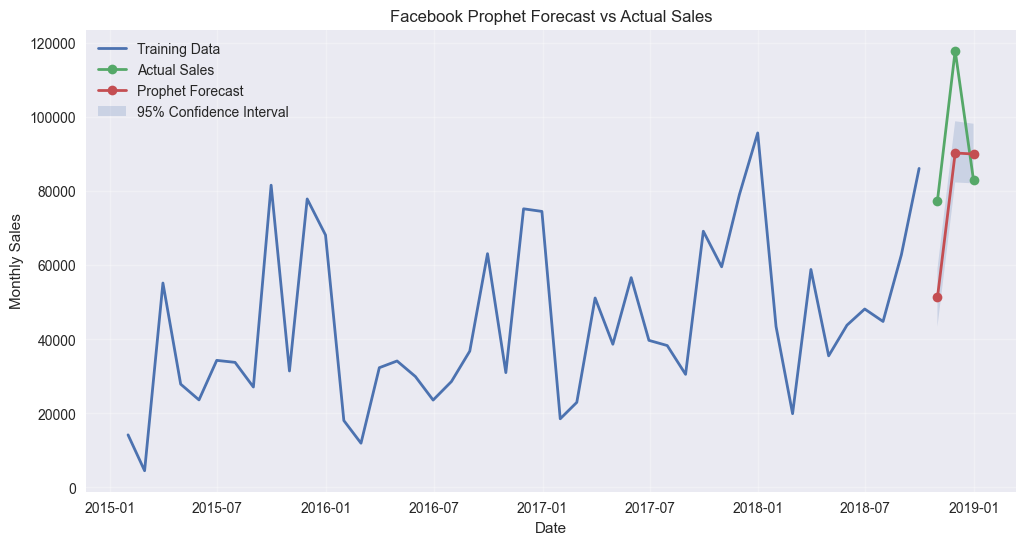

In [85]:
plt.figure(figsize=(12,6))

plt.plot(
    train.index,
    train,
    label='Training Data',
    linewidth=2
)

plt.plot(
    test.index,
    test,
    marker='o',
    linewidth=2,
    label='Actual Sales'
)

plt.plot(
    test.index,
    prophet_pred,
    marker='o',
    linewidth=2,
    label='Prophet Forecast'
)

plt.fill_between(
    forecast['ds'].tail(3),
    forecast['yhat_lower'].tail(3),
    forecast['yhat_upper'].tail(3),
    alpha=0.2,
    label='95% Confidence Interval'
)

plt.title("Facebook Prophet Forecast vs Actual Sales")

plt.xlabel("Date")

plt.ylabel("Monthly Sales")

plt.legend()

plt.grid(alpha=0.3)

plt.show()

### Extract and interpret the weekly and yearly seasonality components

- Yearly Seasonality Interpretation :

The yearly seasonality plot indicates that sales follow a recurring annual pattern. Some months consistently contribute positively to sales, while others show lower-than-average demand. This suggests that customer purchasing behavior is seasonal, and businesses can use this information to plan inventory, marketing campaigns, and staffing during peak and off-peak periods.

- Weekly Seasonality Interpretation :

The weekly seasonality component shows that sales vary noticeably across different days of the week. According to the Prophet model, Wednesday has the strongest positive seasonal effect, indicating that sales tend to be highest around the middle of the week. Friday also shows a positive contribution to sales, although smaller than Wednesday. In contrast, Monday exhibits the largest negative seasonal effect, suggesting that sales are typically lower at the beginning of the week. Sales gradually improve after Monday, remain relatively stable around Thursday, and decrease slightly on Saturday before rising again on Sunday. These patterns indicate that customer purchasing behavior changes throughout the week and can be used to optimize promotions, staffing, and inventory planning.

### Model 3 — XGBoost for Time Series (ML-based Approach)

### Convert Time Series into a Supervised Learning Problem

Unlike SARIMA and Prophet, XGBoost cannot directly understand time series. Therefore, we create features from past observations so that each row contains information useful for predicting the next month's sales.

Features to Create
- Lag 1: Sales from 1 month ago
- Lag 2: Sales from 2 months ago
- Lag 3: Sales from 3 months ago
- Rolling Mean: Average sales over the previous 3 months
- Month
- Quarter
- Season

In [86]:
# Create DataFrame
ts_df = monthly_ts.to_frame(name='Sales')

# Lag Features
ts_df['Lag_1'] = ts_df['Sales'].shift(1)
ts_df['Lag_2'] = ts_df['Sales'].shift(2)
ts_df['Lag_3'] = ts_df['Sales'].shift(3)

# Rolling Mean
ts_df['Rolling_Mean_3'] = (
    ts_df['Sales']
    .rolling(window=3)
    .mean()
    .shift(1)
)

# Calendar Features
ts_df['Month'] = ts_df.index.month
ts_df['Quarter'] = ts_df.index.quarter

# Season
def get_season(month):
    if month in [12,1,2]:
        return 0      # Winter
    elif month in [3,4,5]:
        return 1      # Spring
    elif month in [6,7,8]:
        return 2      # Summer
    else:
        return 3      # Autumn

ts_df['Season'] = ts_df['Month'].apply(get_season)

ts_df.dropna(inplace=True)

ts_df.head()

,Sales,Lag_1,Lag_2,Lag_3,Rolling_Mean_3,Month,Quarter,Season
Order Date,,,,,,,,
2015-04-30,27906.8550,55205.7970,4519.8920,14205.707,24643.798667,4,2,1
2015-05-31,23644.3030,27906.8550,55205.7970,4519.892,29210.848000,5,2,1
2015-06-30,34322.9356,23644.3030,27906.8550,55205.797,35585.651667,6,2,2
2015-07-31,33781.5430,34322.9356,23644.3030,27906.855,28624.697867,7,3,2
2015-08-31,27117.5365,33781.5430,34322.9356,23644.303,30582.927200,8,3,2


In [87]:
# Train Test Split
train_ml = ts_df.iloc[:-3]
test_ml = ts_df.iloc[-3:]

X_train = train_ml.drop(columns='Sales')
y_train = train_ml['Sales']

X_test = test_ml.drop(columns='Sales')
y_test = test_ml['Sales']

In [88]:
# Train XGBoost

from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators = 200,
    learning_rate = 0.05,
    max_depth = 3,
    objective = 'reg:squarederror',
    random_state = 42
)

xgb_model.fit(X_train, y_train)

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes

In [89]:
# Predict the Last 3 Months

xgb_pred = xgb_model.predict(X_test)

xgb_pred

array([68952.87, 87130.1 , 66202.34], dtype=float32)

In [90]:
# Evalutaion

xgb_mae = mean_absolute_error(
    y_test,
    xgb_pred
)

xgb_rmse = root_mean_squared_error(
        y_test,
        xgb_pred
    )

xgb_mape = mean_absolute_percentage_error(
    y_test,
    xgb_pred
)

print("MAE :", xgb_mae)
print("RMSE :", xgb_rmse)
print(f"MAPE : {xgb_mape*100:.2f}%")

MAE : 18710.454166666666
RMSE : 20852.56792703449
MAPE : 19.12%


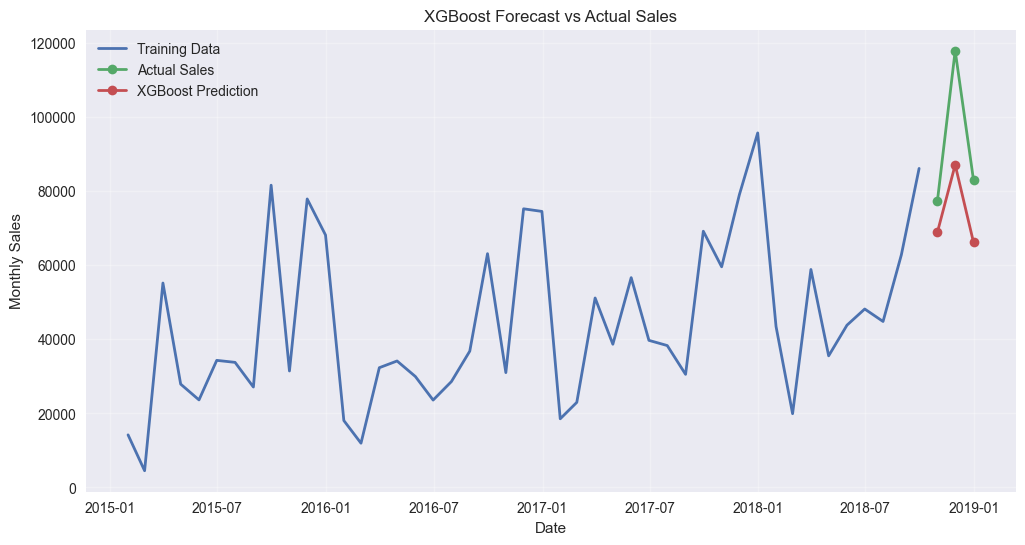

In [91]:
# Plot Actual vs Predicted

plt.figure(figsize=(12,6))

plt.plot(
    train.index,
    train,
    label='Training Data',
    linewidth=2
)

plt.plot(
    y_test.index,
    y_test,
    marker='o',
    linewidth=2,
    label='Actual Sales'
)

plt.plot(
    y_test.index,
    xgb_pred,
    marker='o',
    linewidth=2,
    label='XGBoost Prediction'
)

plt.title("XGBoost Forecast vs Actual Sales")

plt.xlabel("Date")

plt.ylabel("Monthly Sales")

plt.legend()

plt.grid(alpha=0.3)

plt.show()

In [92]:
# Feature Importance
importance = (
    pd.DataFrame({
        'Feature': X_train.columns,
        'Importance': xgb_model.feature_importances_
    })
    .sort_values('Importance', ascending=False)
)

importance

,Feature,Importance
4,Month,0.738733
3,Rolling_Mean_3,0.084278
1,Lag_2,0.079987
0,Lag_1,0.054607
2,Lag_3,0.038876
6,Season,0.003518
5,Quarter,0.000000


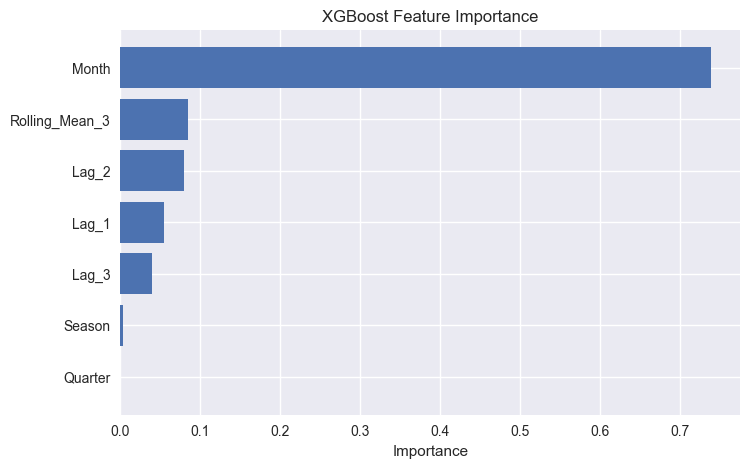

In [93]:
plt.figure(figsize=(8,5))

plt.barh(
    importance['Feature'],
    importance['Importance']
)

plt.title("XGBoost Feature Importance")

plt.xlabel("Importance")

plt.gca().invert_yaxis()

plt.show()

In [94]:
#  Model Comparison Table

comparison = pd.DataFrame({
    "Model": ["SARIMA", "Facebook Prophet", "XGBoost"],
    "MAE": [
        round(sarima_mae,2),
        round(prophet_mae,2),
        round(xgb_mae,2)
    ],
    "RMSE": [
        round(sarima_rmse,2),
        round(prophet_rmse,2),
        round(xgb_rmse,2)
    ],
    "MAPE (%)": [
        round(sarima_mape*100,2),
        round(prophet_mape*100,2),
        round(xgb_mape*100,2)
    ],
    "Forecast Month 1": [
        round(sarima_pred.iloc[0],2),
        round(prophet_pred[0],2),
        round(xgb_pred[0],2)
    ],
    "Forecast Month 2": [
        round(sarima_pred.iloc[1],2),
        round(prophet_pred[1],2),
        round(xgb_pred[1],2)
    ],
    "Forecast Month 3": [
        round(sarima_pred.iloc[2],2),
        round(prophet_pred[2],2),
        round(xgb_pred[2],2)
    ]
})

comparison

,Model,MAE,RMSE,MAPE (%),Forecast Month 1,Forecast Month 2,Forecast Month 3
0,SARIMA,18031.40,19009.18,18.97,66177.600000,92049.250000,99965.17000
1,Facebook Prophet,20250.79,22318.41,21.86,51318.940000,90325.650000,90041.08000
2,XGBoost,18710.45,20852.57,19.12,68952.859375,87130.101562,66202.34375


### State clearly which model you would recommend for production use and why based on numbers, not preference.



- Based on the evaluation metrics, SARIMA is the recommended model for production use. It achieved the lowest Mean Absolute Error (MAE = 18,031.40), lowest Root Mean Squared Error (RMSE = 19,009.18), and lowest Mean Absolute Percentage Error (MAPE = 18.97%) among all three forecasting models. These results indicate that SARIMA produced the most accurate and reliable forecasts for this dataset. Although XGBoost delivered competitive performance, its MAE, RMSE, and MAPE were slightly higher than those of SARIMA. Facebook Prophet successfully captured the overall trend and seasonality but recorded the highest forecasting errors. Therefore, based on objective performance metrics rather than personal preference, SARIMA is the most suitable model for production deployment for demand forecasting, inventory planning, and business decision-making.

# 4. Product Category & Region Level Forecasting
-  Create Monthly Sales Series for Each Segment

In [95]:
# Furniture
furniture = df[df['Category'] == 'Furniture']

furniture_ts = (
    furniture
    .groupby(pd.Grouper(key='Order Date', freq='M'))['Sales']
    .sum()
)

In [96]:
# Technology
technology = df[df['Category'] == 'Technology']

technology_ts = (
    technology
    .groupby(pd.Grouper(key='Order Date', freq='M'))['Sales']
    .sum()
)

In [97]:
# Office Supplies
office = df[df['Category'] == 'Office Supplies']

office_ts = (
    office
    .groupby(pd.Grouper(key='Order Date', freq='M'))['Sales']
    .sum()
)

In [98]:
# West Region
west = df[df['Region'] == 'West']

west_ts = (
    west
    .groupby(pd.Grouper(key='Order Date', freq='M'))['Sales']
    .sum()
)

In [99]:
# East Region 
east = df[df['Region'] == 'East']

east_ts = (
    east
    .groupby(pd.Grouper(key='Order Date', freq='M'))['Sales']
    .sum()
)

In [100]:
# SARIMA Function
def sarima_forecast(ts):

    train = ts[:-3]

    model = SARIMAX(
        train,
        order=(1,1,1),
        seasonal_order=(1,1,1,12)
    )

    fit = model.fit(disp=False)

    forecast = fit.get_forecast(steps=3)

    return forecast.predicted_mean

In [101]:
# Forecast Every Segment
furniture_pred = sarima_forecast(furniture_ts)

technology_pred = sarima_forecast(technology_ts)

office_pred = sarima_forecast(office_ts)

west_pred = sarima_forecast(west_ts)

east_pred = sarima_forecast(east_ts)

In [102]:
# Combine Forecasts
forecast_df = pd.DataFrame({
    "Furniture": furniture_pred,
    "Technology": technology_pred,
    "Office Supplies": office_pred,
    "West": west_pred,
    "East": east_pred
})

forecast_df

,Furniture,Technology,Office Supplies,West,East
2018-10-31,14106.841096,22307.792269,19633.401374,24332.451655,25330.845642
2018-11-30,33473.219539,31172.695455,28435.046569,28312.250055,35283.047554
2018-12-31,31818.755889,32068.917085,31686.945014,39442.764465,36009.452929


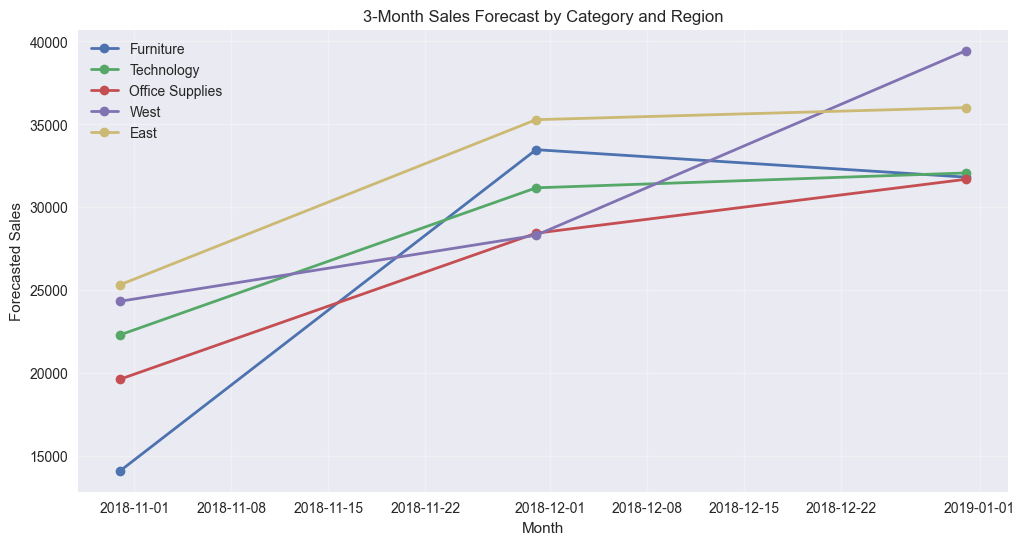

In [103]:
# Plot All Forecasts Together
plt.figure(figsize=(12,6))

for col in forecast_df.columns:
    plt.plot(
        forecast_df.index,
        forecast_df[col],
        marker='o',
        linewidth=2,
        label=col
    )

plt.title("3-Month Sales Forecast by Category and Region")

plt.xlabel("Month")

plt.ylabel("Forecasted Sales")

plt.legend()

plt.grid(alpha=0.3)

plt.show()

In [104]:
growth = forecast_df.iloc[-1] - forecast_df.iloc[0]

growth.sort_values(ascending=False)

Furniture          17711.914793
West               15110.312810
Office Supplies    12053.543640
East               10678.607287
Technology          9761.124817
dtype: float64

In [105]:
growth_percent = (
    (forecast_df.iloc[-1] - forecast_df.iloc[0])
    /
    forecast_df.iloc[0]
) * 100

growth_percent.sort_values(ascending=False)

Furniture          125.555499
West                62.099426
Office Supplies     61.393049
Technology          43.756570
East                42.156537
dtype: float64

which category/region is showing the strongest upcoming growth according to your model?

- Based on the SARIMA forecasts, Furniture is expected to show the strongest upcoming growth among all product categories, with an absolute increase of 17,711.91 in forecasted sales over the next three months, representing approximately 125.56% growth. This indicates a substantial increase in demand, making Furniture the highest-growth category in the forecast period.

- Among the regions, the West region is projected to experience the strongest growth, with an absolute increase of 15,110.31 in sales and a 62.10% growth rate, outperforming the East region. This suggests that the West region is likely to contribute the most to future sales expansion.

- Overall, the forecast indicates that Furniture products in the West region present the greatest growth opportunity. Businesses should prioritize inventory planning, marketing campaigns, and resource allocation toward these segments to maximize future revenue.


# 5. Anomaly Detection in Sales Data

- Anomaly Detection is the process of identifying unusual observations that differ significantly from the normal pattern of data. In sales forecasting, anomalies may occur due to festive seasons, promotional campaigns, supply chain disruptions, or unexpected market events. Detecting these anomalies helps businesses investigate unusual sales behavior and improve future forecasting models.

In [106]:
# Create Weekly Sales Series
weekly_sales = (
    df.groupby(pd.Grouper(key='Order Date', freq='W'))['Sales']
      .sum()
      .reset_index()
)

weekly_sales.head()

,Order Date,Sales
0,2015-01-04,304.508
1,2015-01-11,4619.108
2,2015-01-18,4130.533
3,2015-01-25,3092.544
4,2015-02-01,2527.914


In [107]:
# Train Isolation Forest
from sklearn.ensemble import IsolationForest

iso = IsolationForest(
    contamination=0.05,
    random_state=42
)

weekly_sales['Anomaly_IF'] = iso.fit_predict(
    weekly_sales[['Sales']]
)

weekly_sales.head()

,Order Date,Sales,Anomaly_IF
0,2015-01-04,304.508,-1
1,2015-01-11,4619.108,1
2,2015-01-18,4130.533,1
3,2015-01-25,3092.544,1
4,2015-02-01,2527.914,1


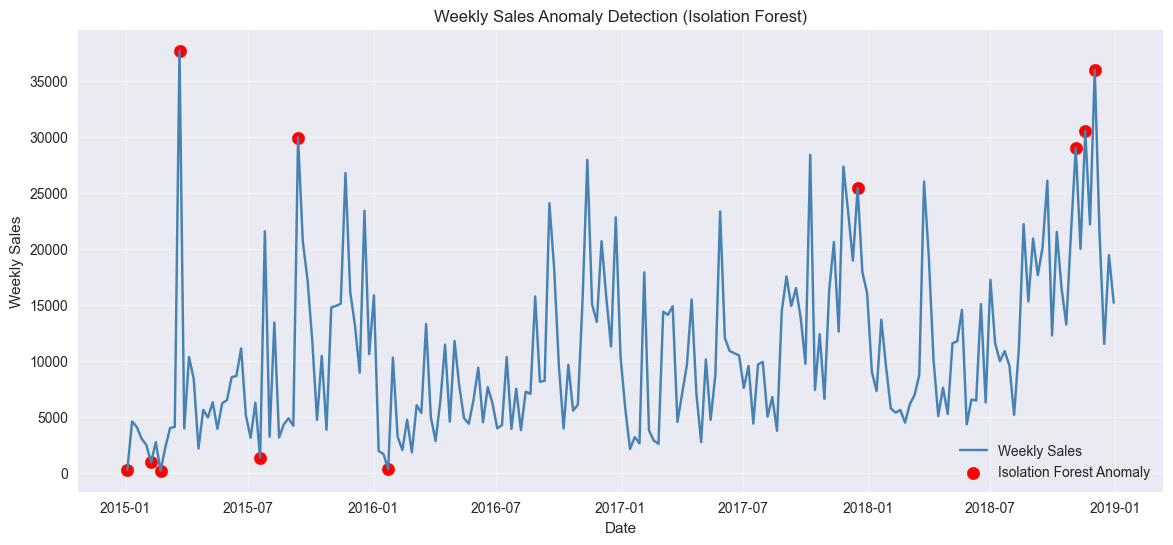

In [108]:
# Plot Anomalies
plt.figure(figsize=(14,6))

plt.plot(
    weekly_sales['Order Date'],
    weekly_sales['Sales'],
    color='steelblue',
    label='Weekly Sales'
)

anomalies = weekly_sales[
    weekly_sales['Anomaly_IF']==-1
]

plt.scatter(
    anomalies['Order Date'],
    anomalies['Sales'],
    color='red',
    s=80,
    marker='o',
    label='Isolation Forest Anomaly'
)

plt.title("Weekly Sales Anomaly Detection (Isolation Forest)")

plt.xlabel("Date")

plt.ylabel("Weekly Sales")

plt.legend()

plt.grid(alpha=0.3)

plt.show()

##  For each detected anomaly, write a possible real-world explanation (e.g., "spike in November likely corresponds to a festive sale period")


| Type of Anomaly                             | Possible Business Explanation                                                                                               |
| ------------------------------------------- | --------------------------------------------------------------------------------------------------------------------------- |
| Very high sales spikes                      | Likely caused by festive seasons, year-end sales, Black Friday promotions, holiday shopping, or large bulk customer orders. |
| Extremely low sales weeks                   | Could be due to post-holiday demand decline, temporary stock shortages, fewer business days, or reduced customer activity.  |
| Consecutive high sales near the end of 2018 | Indicates strong seasonal demand during the holiday shopping period and year-end promotional campaigns.                     |
| Isolated low sales points                   | May represent supply chain disruptions, inventory shortages, operational issues, or temporary market slowdowns.             |


- Isolation Forest detected several weeks with unusually high and unusually low sales compared to the overall sales pattern. Most of the high-sales anomalies occur toward the end of the year, which is consistent with festive seasons, holiday shopping, and promotional campaigns. On the other hand, unusually low sales weeks may be associated with post-holiday demand declines, inventory shortages, or temporary operational disruptions. These anomalies represent business events that differ significantly from normal sales behavior and should be investigated before making forecasting decisions.

# 

In [109]:
# Rolling Mean & Rolling Standard Deviation
window = 4

weekly_sales['Rolling_Mean'] = (
    weekly_sales['Sales']
    .rolling(window=window)
    .mean()
)

weekly_sales['Rolling_STD'] = (
    weekly_sales['Sales']
    .rolling(window=window)
    .std()
)

In [110]:
# Calculate Z-Score

weekly_sales['Z_Score'] = (
    (weekly_sales['Sales'] - weekly_sales['Rolling_Mean'])
    / weekly_sales['Rolling_STD']
)

In [111]:
# Flag Anomalies (|Z| > 2)
weekly_sales['Anomaly_Z'] = weekly_sales['Z_Score'].abs() > 2

In [112]:
# View Detected Anomalies
z_anomalies = weekly_sales[
    weekly_sales['Anomaly_Z']
]

z_anomalies[['Order Date','Sales','Z_Score']]

,Order Date,Sales,Z_Score


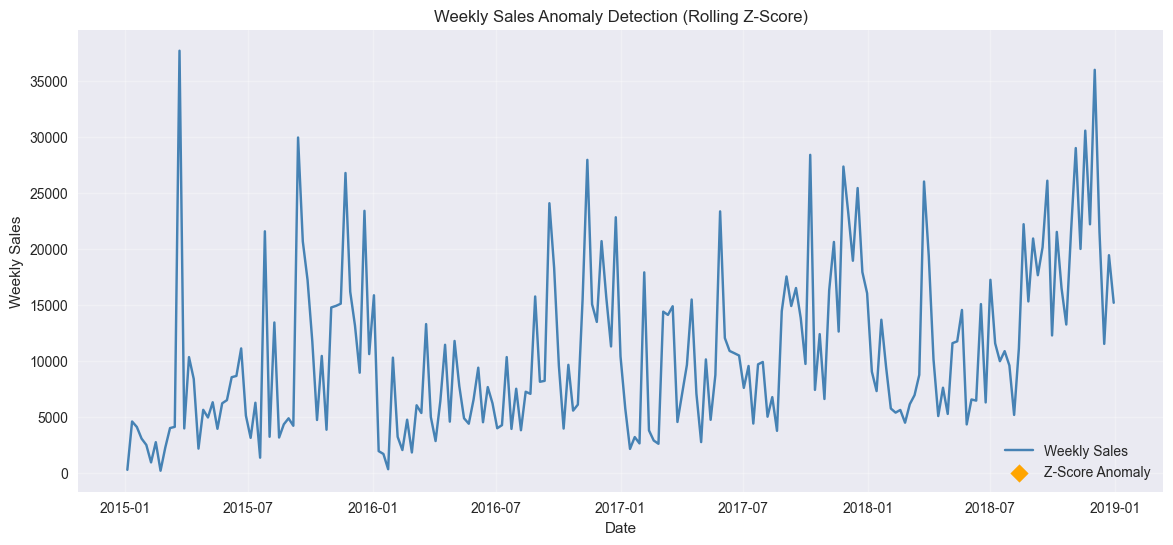

In [113]:
# Plot Z-Score Anomalies
plt.figure(figsize=(14,6))

plt.plot(
    weekly_sales['Order Date'],
    weekly_sales['Sales'],
    color='steelblue',
    label='Weekly Sales'
)

plt.scatter(
    z_anomalies['Order Date'],
    z_anomalies['Sales'],
    color='orange',
    marker='D',
    s=80,
    label='Z-Score Anomaly'
)

plt.title("Weekly Sales Anomaly Detection (Rolling Z-Score)")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")

plt.legend()

plt.grid(alpha=0.3)

plt.show()

In [114]:
# Compare Both Methods

comparison = weekly_sales[
    ['Order Date','Sales','Anomaly_IF','Anomaly_Z']
]

comparison.head()

,Order Date,Sales,Anomaly_IF,Anomaly_Z
0,2015-01-04,304.508,-1,False
1,2015-01-11,4619.108,1,False
2,2015-01-18,4130.533,1,False
3,2015-01-25,3092.544,1,False
4,2015-02-01,2527.914,1,False


In [115]:
# Isolation Forest
if_dates = weekly_sales.loc[
    weekly_sales['Anomaly_IF'] == -1,
    'Order Date'
]

# Z-Score
z_dates = weekly_sales.loc[
    weekly_sales['Anomaly_Z'],
    'Order Date'
]

print("Isolation Forest:", len(if_dates))
print("Z-Score:", len(z_dates))

Isolation Forest: 11
Z-Score: 0


In [116]:
common = weekly_sales[
    (weekly_sales['Anomaly_IF'] == -1) &
    (weekly_sales['Anomaly_Z'])
]

common[['Order Date','Sales']]

,Order Date,Sales


Do both methods flag the same anomalies, or do they disagree?
- The two anomaly detection methods disagree in this analysis. Isolation Forest detected 11 anomalous weeks, while the Rolling Z-Score method detected 0 anomalies using the threshold of more than 2 standard deviations from the rolling mean. Therefore, there were no common anomalies identified by both methods.

What does this tell you?
- This difference shows that anomaly detection results depend strongly on the method used. Isolation Forest was more sensitive to unusual sales patterns and detected both unusually high and unusually low sales weeks based on the overall distribution of the data. In contrast, the Rolling Z-Score method was more conservative, and none of the weekly sales values exceeded the ±2 standard deviation threshold relative to their rolling mean. This suggests that the detected sales anomalies were unusual in the broader data distribution but were not extreme enough relative to their recent local sales pattern to be flagged by the Z-Score method. Therefore, using multiple anomaly detection methods can provide a more complete understanding of unusual sales behaviour.

- Isolation Forest: 11 anomalies
- Rolling Z-Score (|Z| > 2): 0 anomalies
- Common anomalies: 0

# 6.  Product Demand Segmentation using Clustering

In [117]:
# Monthly Sales by Sub-Category
monthly_product = (
    df.groupby([
        'Sub-Category',
        pd.Grouper(key='Order Date', freq='M')
    ])['Sales']
    .sum()
    .reset_index()
)

In [118]:
# Total Sales Volume and Sales Volatility
product_features = (
    monthly_product
    .groupby('Sub-Category')['Sales']
    .agg(
        Total_Sales='sum',
        Sales_Volatility='std'
    )
)

In [119]:
# Average Order Value
avg_order_value = (
    df.groupby('Sub-Category')['Sales']
    .mean()
    .rename('Average_Order_Value')
)

product_features = product_features.join(avg_order_value)

In [120]:
# Year-over-Year Sales Growth Rate
yearly_sales = (
    df.groupby([
        'Sub-Category',
        df['Order Date'].dt.year
    ])['Sales']
    .sum()
    .unstack()
)

yoy_growth = yearly_sales.pct_change(axis=1) * 100

product_features['YoY_Growth'] = yoy_growth.mean(axis=1)

In [121]:
product_features

,Total_Sales,Sales_Volatility,Average_Order_Value,YoY_Growth
Sub-Category,,,,
Accessories,164186.7000,2579.994809,217.178175,37.638071
Appliances,104618.4030,1821.621539,227.926804,39.927584
Art,26705.4100,330.488343,34.019631,16.605553
Binders,200028.7850,3848.223648,134.067550,21.873607
Bookcases,113813.1987,2220.405080,503.598224,23.806516
Chairs,322822.7310,4407.232960,531.833165,7.135790
Copiers,146248.0940,5500.774391,2215.880212,84.671819
Envelopes,16128.0460,228.218688,65.032444,-2.766643
Fasteners,3001.9600,48.742229,14.027850,15.703383


In [122]:
# Handle Missing or Infinite Values
import numpy as np

product_features.replace([np.inf, -np.inf], np.nan, inplace=True)
product_features.fillna(0, inplace=True)

In [123]:
# Standardize the Features
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(product_features)

- The features were standardized before applying K-Means because they have different numerical scales. Without scaling, features with larger values, such as total sales, could dominate the clustering process.

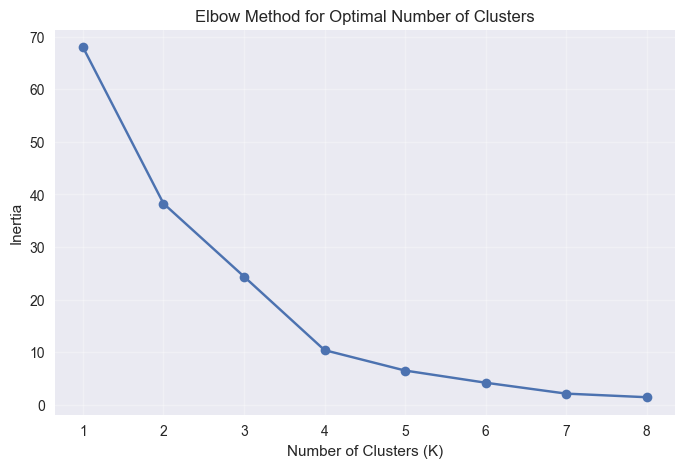

In [124]:
# the Elbow Method to find the optimal number of clusters
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

K = range(1, 9)

for k in K:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8,5))

plt.plot(K, inertia, marker='o')

plt.title('Elbow Method for Optimal Number of Clusters')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(K)
plt.grid(alpha=0.3)

plt.show()

- The Elbow Method was used to determine the optimal number of clusters. The graph shows a significant decrease in inertia as the number of clusters increases from 1 to 4. After K = 4, the reduction in inertia becomes much smaller, indicating diminishing improvement from adding more clusters. Therefore, 4 clusters were selected as the optimal number for product demand segmentation.

In [125]:
# K-Means Clustering to segment products into demand groups
optimal_k = 4

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

product_features['Cluster'] = kmeans.fit_predict(X_scaled)

In [126]:
cluster_summary = product_features.groupby('Cluster')[
    ['Total_Sales',
     'Sales_Volatility',
     'Average_Order_Value',
     'YoY_Growth']
].mean()

cluster_summary

,Total_Sales,Sales_Volatility,Average_Order_Value,YoY_Growth
Cluster,,,,
0,167743.362500,5552.164569,1930.716763,46.338910
1,55331.883212,907.223743,129.054568,19.958882
2,239495.780667,3489.056075,361.131228,18.096484
3,46420.308000,2025.094139,252.284283,192.844843


| Cluster | Key Pattern                                         | Recommended Label                |
| ------- | --------------------------------------------------- | -------------------------------- |
| **0**   | High sales, highest volatility, strong 46.3% growth | **High Volume, High Volatility** |
| **1**   | Low sales, lowest volatility, moderate 20.0% growth | **Low Volume, Stable Demand**    |
| **2**   | Highest sales, moderate volatility, 18.1% growth    | **High Volume, Stable Demand**   |
| **3**   | Lowest sales but extremely high 192.8% growth       | **Rapidly Growing Demand**       |


In [127]:
# labels
cluster_labels = {
    0: 'High Volume, High Volatility',
    1: 'Low Volume, Stable Demand',
    2: 'High Volume, Stable Demand',
    3: 'Rapidly Growing Demand'
}

product_features['Demand_Segment'] = (
    product_features['Cluster'].map(cluster_labels)
)

product_features[
    ['Total_Sales',
     'Sales_Volatility',
     'Average_Order_Value',
     'YoY_Growth',
     'Cluster',
     'Demand_Segment']
]

,Total_Sales,Sales_Volatility,Average_Order_Value,YoY_Growth,Cluster,Demand_Segment
Sub-Category,,,,,,
Accessories,164186.7000,2579.994809,217.178175,37.638071,2,"High Volume, Stable Demand"
Appliances,104618.4030,1821.621539,227.926804,39.927584,1,"Low Volume, Stable Demand"
Art,26705.4100,330.488343,34.019631,16.605553,1,"Low Volume, Stable Demand"
Binders,200028.7850,3848.223648,134.067550,21.873607,2,"High Volume, Stable Demand"
Bookcases,113813.1987,2220.405080,503.598224,23.806516,1,"Low Volume, Stable Demand"
Chairs,322822.7310,4407.232960,531.833165,7.135790,2,"High Volume, Stable Demand"
Copiers,146248.0940,5500.774391,2215.880212,84.671819,0,"High Volume, High Volatility"
Envelopes,16128.0460,228.218688,65.032444,-2.766643,1,"Low Volume, Stable Demand"
Fasteners,3001.9600,48.742229,14.027850,15.703383,1,"Low Volume, Stable Demand"


### Stocking Strategy 

- Cluster 0 – High Volume, High Volatility: These products generate high sales but experience large demand fluctuations. The company should maintain moderate-to-high safety stock while frequently updating demand forecasts to reduce both stockouts and excess inventory.

- Cluster 1 – Low Volume, Stable Demand: These products have relatively low but predictable demand. The company should maintain lean inventory levels and use regular, smaller replenishment orders to minimize holding costs.

- Cluster 2 – High Volume, Stable Demand: These are the most important products for inventory availability because they generate the highest total sales with comparatively stable demand. The company should maintain high service levels, adequate safety stock, and automated replenishment to prevent stockouts.

- Cluster 3 – Rapidly Growing Demand: These products currently have relatively low sales volume but show exceptionally high average YoY growth of 192.8%. Inventory levels should be increased gradually, with frequent demand monitoring to capture growth while avoiding overstocking.

In [128]:
# PCA
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Reduce 4 standardized features to 2 dimensions
pca = PCA(n_components=2)
pca_data = pca.fit_transform(X_scaled)

product_features['PCA1'] = pca_data[:, 0]
product_features['PCA2'] = pca_data[:, 1]

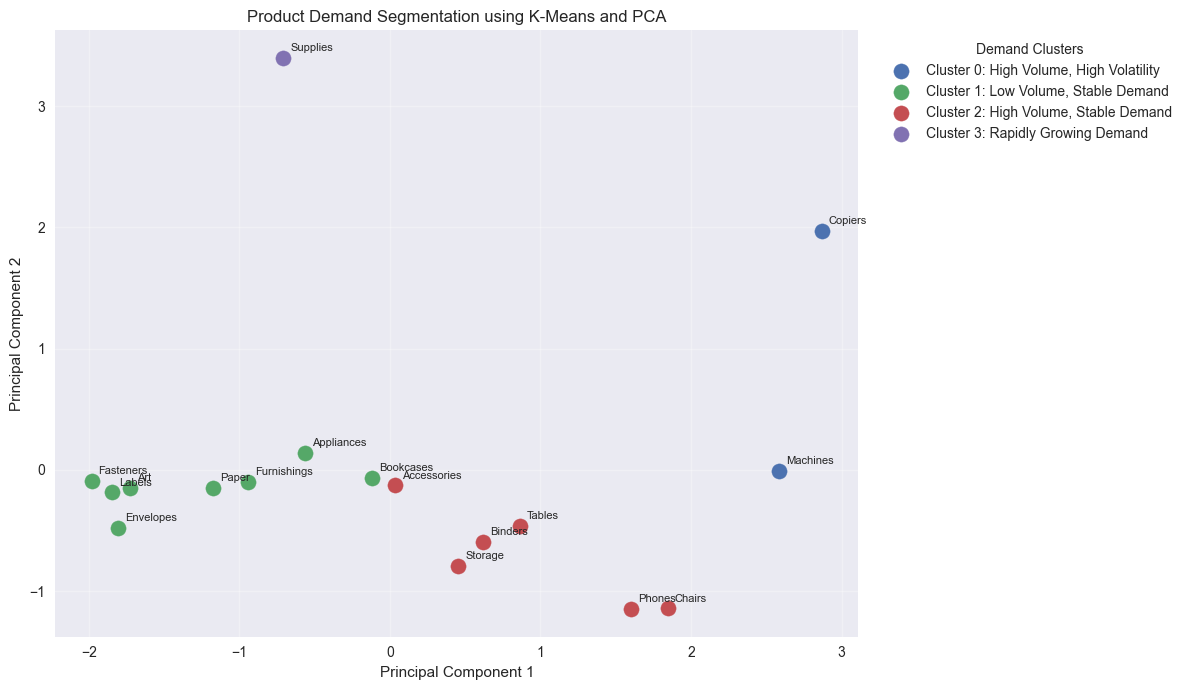

In [129]:
# Plot clusters using a 2D scatter plot 
plt.figure(figsize=(12, 7))

# Plot each cluster separately so it appears in the legend
for cluster_id, cluster_name in cluster_labels.items():

    cluster_data = product_features[
        product_features['Cluster'] == cluster_id
    ]

    plt.scatter(
        cluster_data['PCA1'],
        cluster_data['PCA2'],
        s=120,
        label=f'Cluster {cluster_id}: {cluster_name}'
    )

# Add product sub-category names
for subcategory, row in product_features.iterrows():
    plt.annotate(
        subcategory,
        (row['PCA1'], row['PCA2']),
        xytext=(5, 5),
        textcoords='offset points',
        fontsize=8
    )

plt.title('Product Demand Segmentation using K-Means and PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.legend(
    title='Demand Clusters',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [130]:
top_3_anomalies = (
    weekly_sales[weekly_sales['Anomaly_IF'] == -1]
    .nlargest(3, 'Sales')
    [['Order Date', 'Sales']]
)

top_3_anomalies

,Order Date,Sales
11,2015-03-22,37703.665
204,2018-12-02,35998.900
202,2018-11-18,30572.447
